# POET spectrum

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Load

In [2]:
path = '/Users/sophiestucki/Downloads/poet_spectrum.npz'
data = np.load(path)
for key in data.files:
    print(key, data[key].shape)

wave = data['wave_air']
flux = data['flux']
flux_blaze = data['flux_blaze']
blaze = data['blaze']
n_orders = wave.shape[0]

wave_vac (170, 9111)
wave_air (170, 9111)
flux (170, 9111)
flux_blaze (170, 9111)
blaze (170, 9111)


## All orders

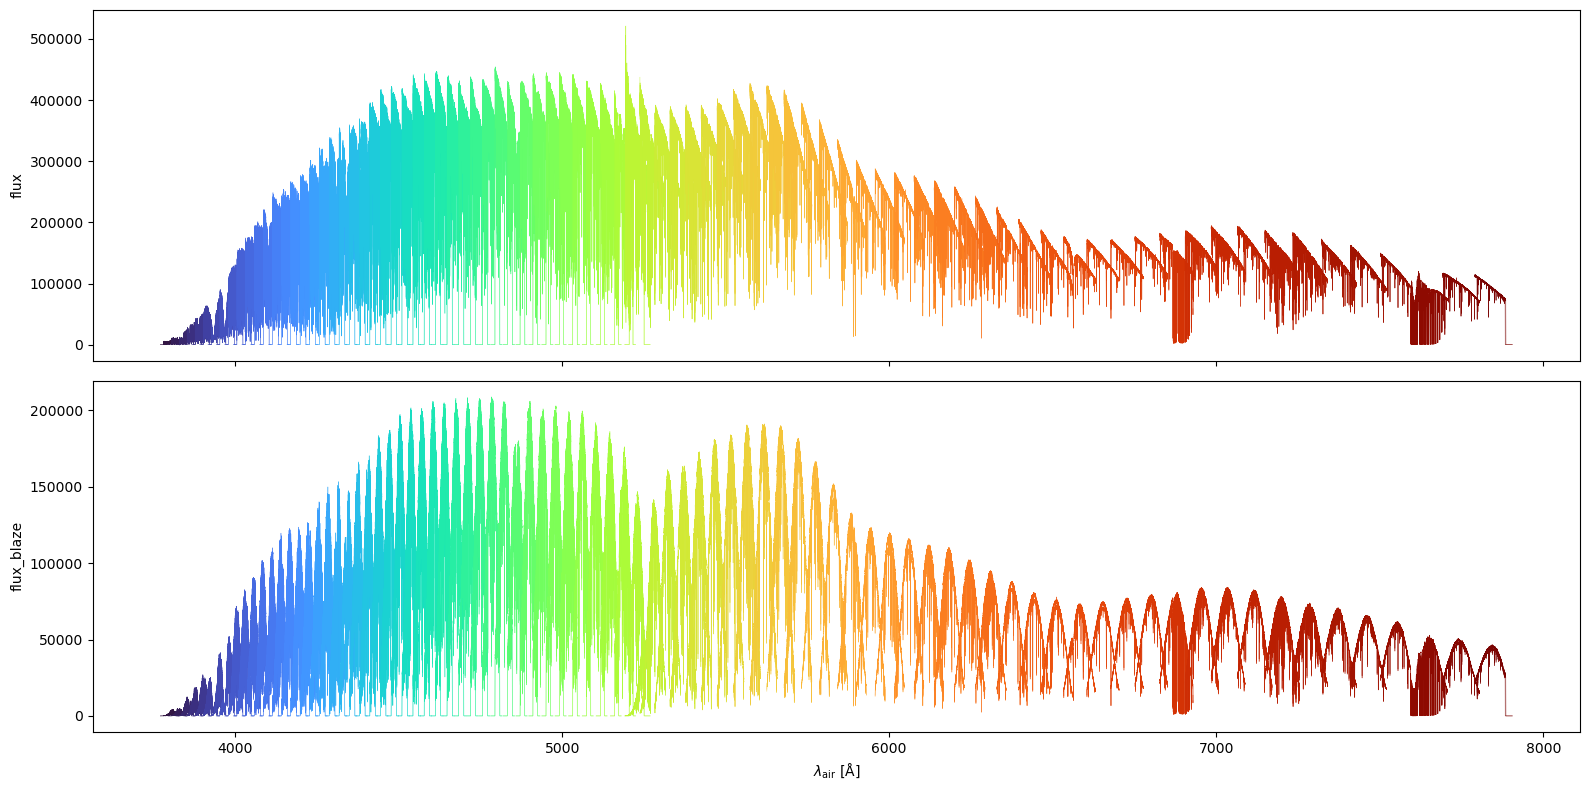

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
cmap = plt.get_cmap('turbo')
for i in range(n_orders):
    color = cmap(i / (n_orders - 1))
    axes[0].plot(wave[i], flux[i], lw=0.3, color=color)
    axes[1].plot(wave[i], flux_blaze[i], lw=0.3, color=color)
axes[0].set_ylabel('flux')
axes[1].set_ylabel('flux_blaze')
axes[1].set_xlabel(r'$\lambda_{\rm air}$ [Å]')
plt.tight_layout()
plt.show()

## Each order

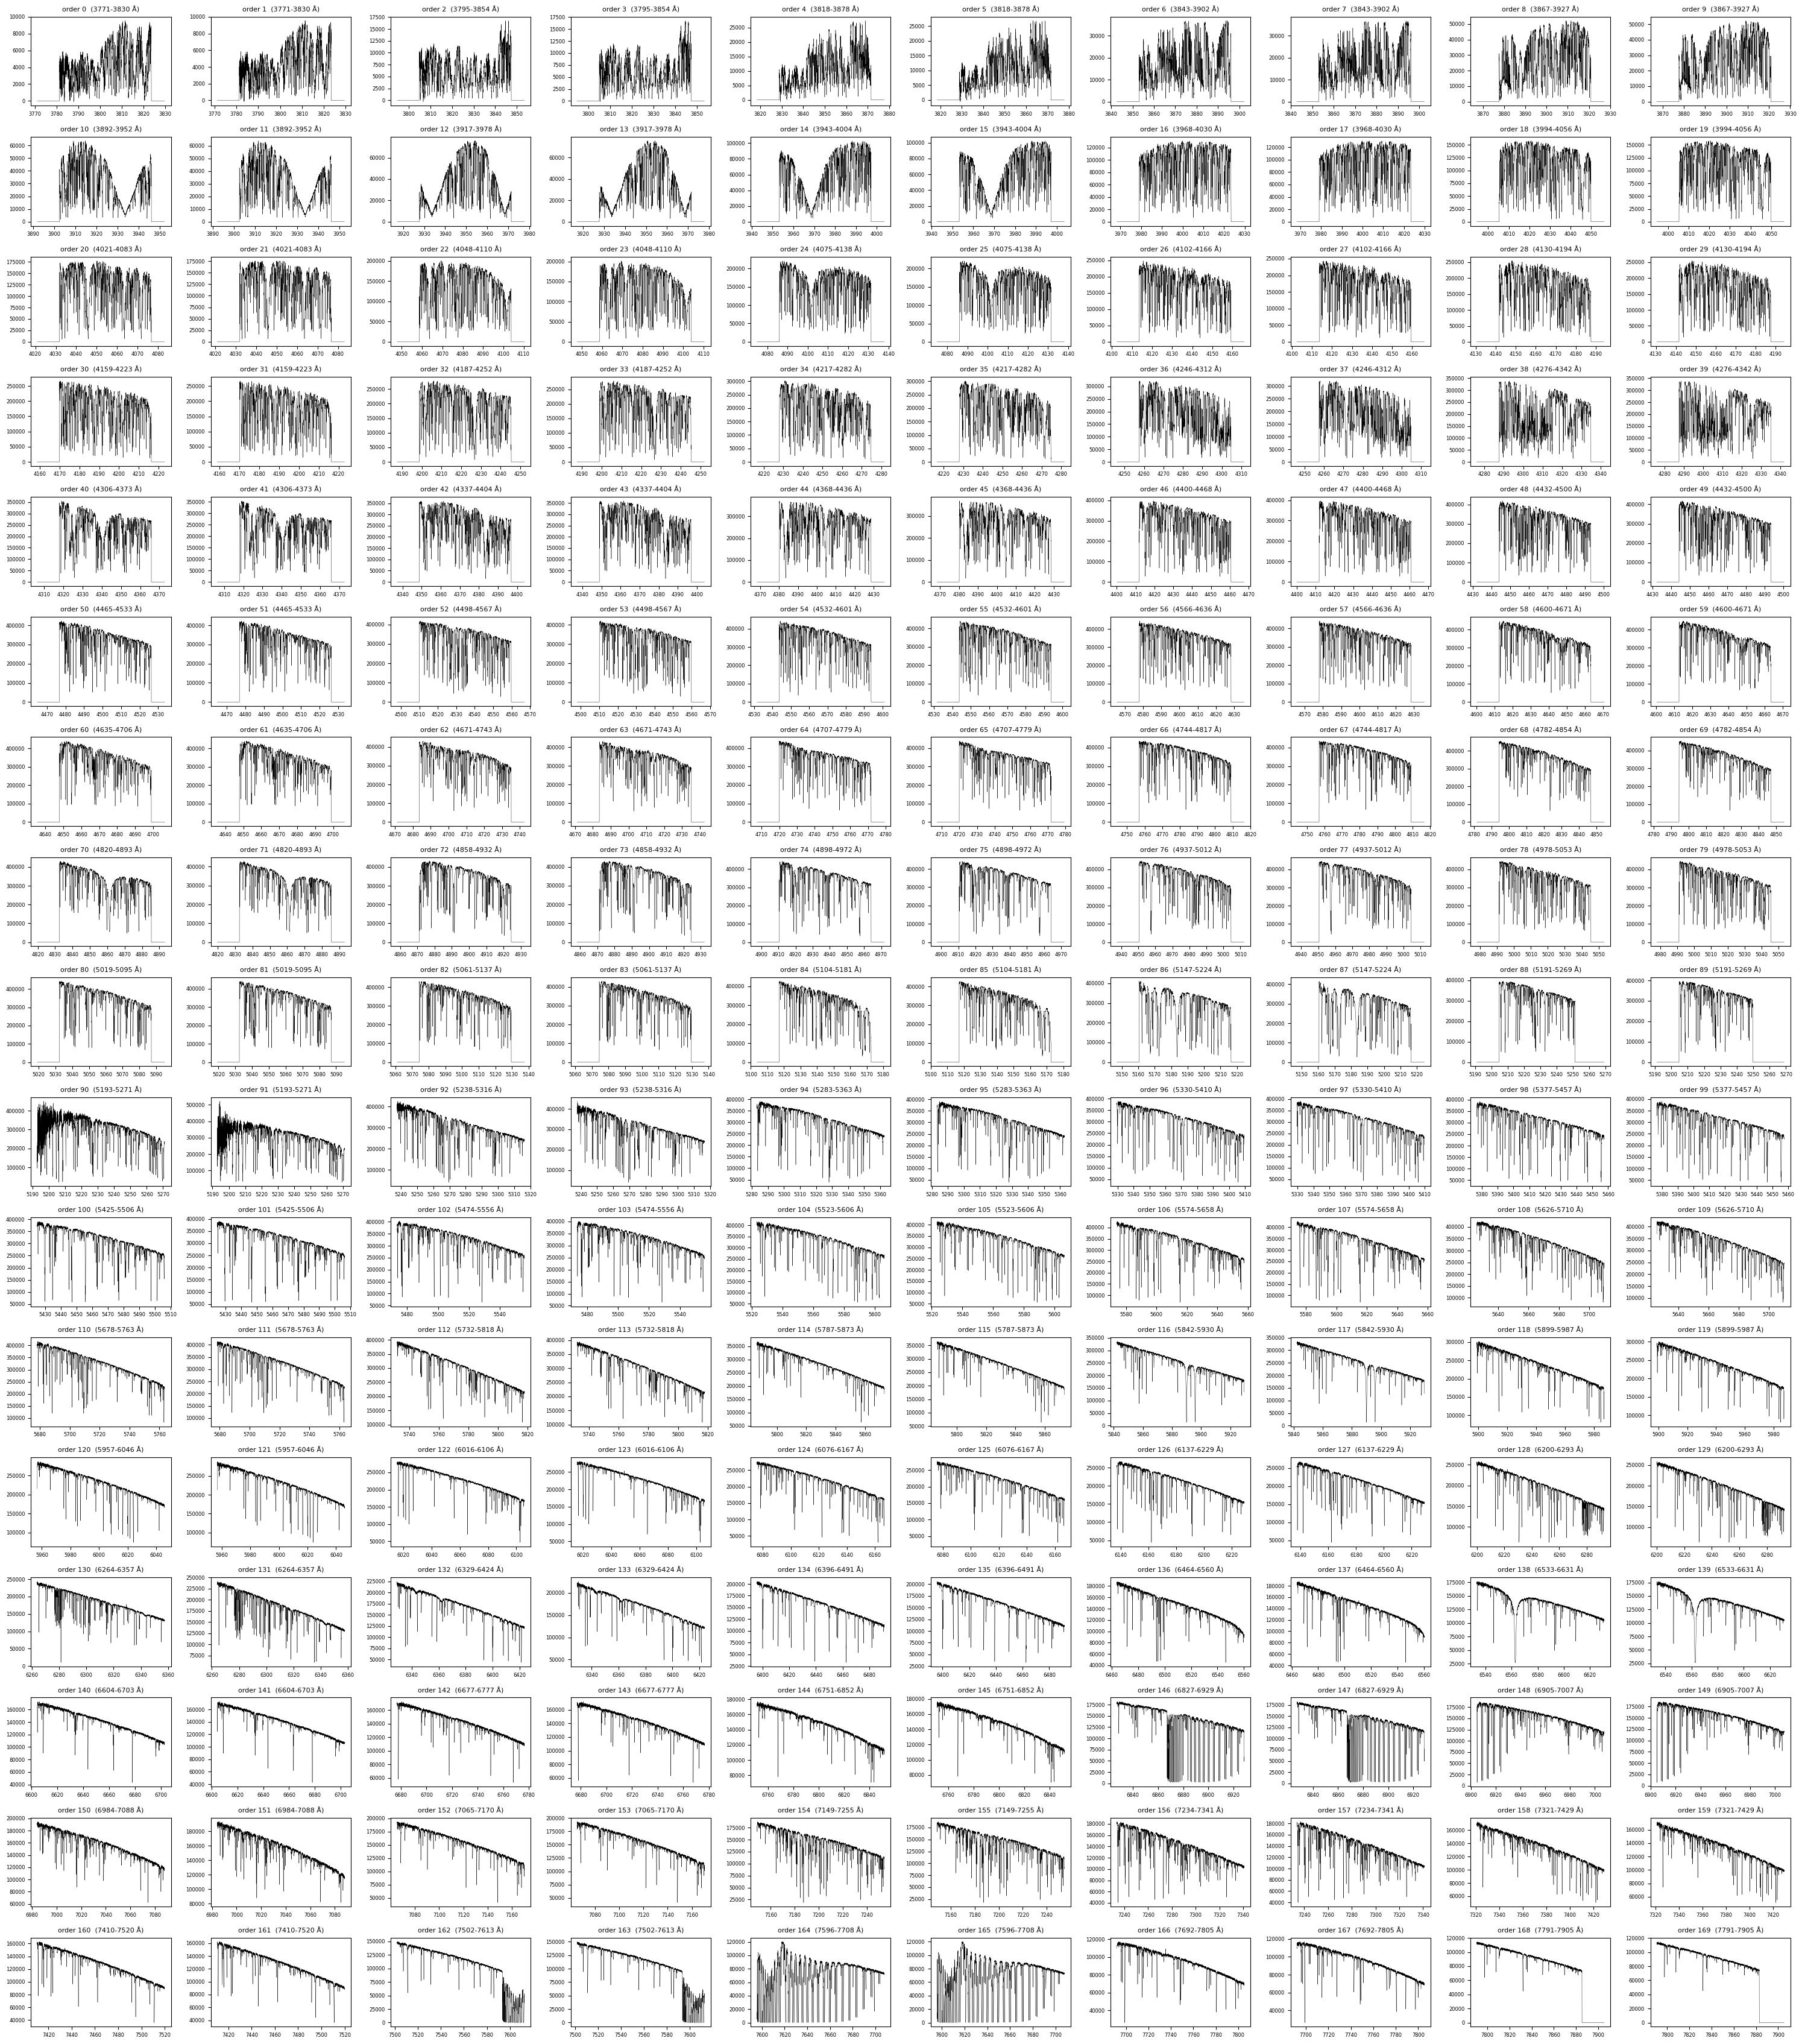

In [4]:
n_cols = 10
n_rows = int(np.ceil(n_orders / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2 * n_rows))
for i, ax in enumerate(axes.flat):
    if i >= n_orders:
        ax.axis('off')
        continue
    ax.plot(wave[i], flux[i], lw=0.3, color='k')
    ax.set_title(f'order {i}  ({wave[i, 0]:.0f}-{wave[i, -1]:.0f} Å)', fontsize=8)
    ax.tick_params(labelsize=6)
plt.tight_layout()
plt.show()

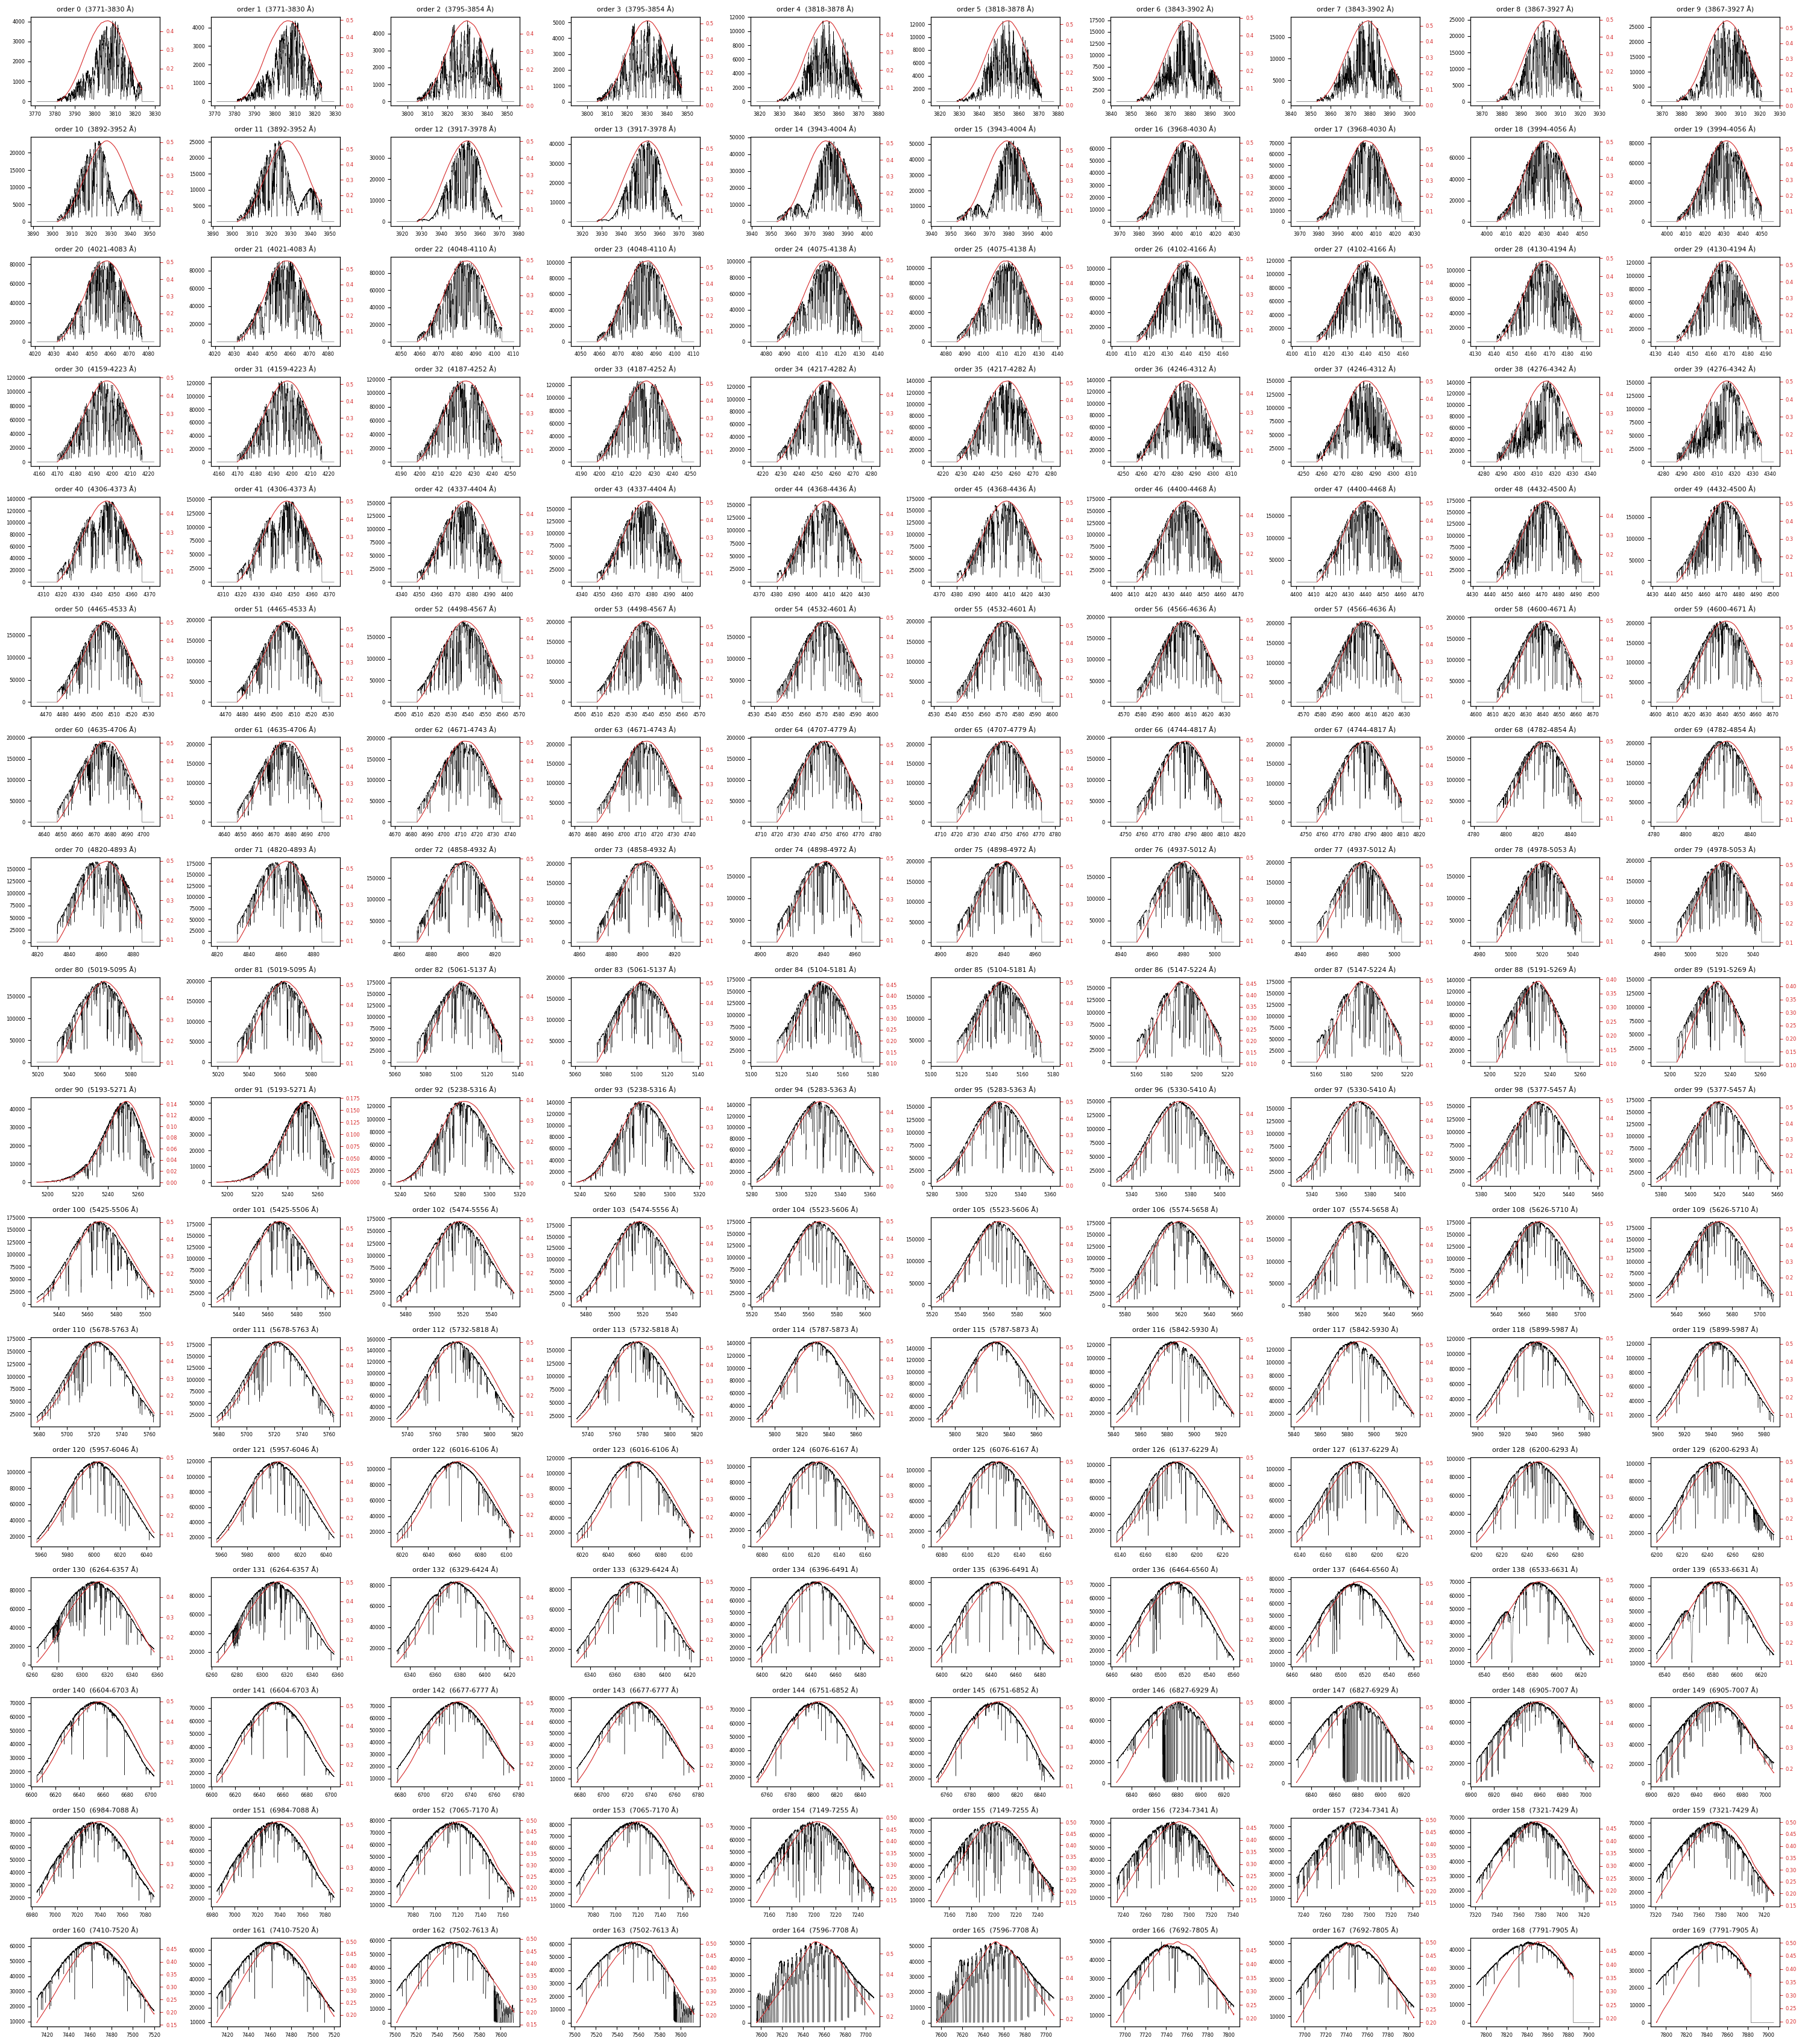

In [5]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2 * n_rows))
for i, ax in enumerate(axes.flat):
    if i >= n_orders:
        ax.axis('off')
        continue
    ax.plot(wave[i], flux_blaze[i], lw=0.3, color='k')
    ax2 = ax.twinx()
    ax2.plot(wave[i], blaze[i], lw=0.8, color='C3')
    ax.set_title(f'order {i}  ({wave[i, 0]:.0f}-{wave[i, -1]:.0f} Å)', fontsize=8)
    ax.tick_params(labelsize=6)
    ax2.tick_params(labelsize=6, colors='C3')
plt.tight_layout()
plt.show()

## Blaze normalised

In [6]:
import sys
sys.path.insert(0, '..')
from sunsim import local_path

top = 0.9    # parabola fitted to the pixels with blaze >= top * max(blaze of the order)

blaze_norm = np.full(blaze.shape, np.nan)
peak = np.zeros(n_orders)
for i in range(n_orders):
    ok = np.isfinite(blaze[i])
    s = ok & (blaze[i] >= top * np.nanmax(blaze[i]))
    x0 = wave[i][s].mean()
    c = np.polyfit(wave[i][s] - x0, blaze[i][s], 2)
    peak[i] = np.polyval(c, wave[i][s] - x0).max()
    blaze_norm[i, ok] = blaze[i][ok] / peak[i]
print('max of the normalised blaze: %.4f-%.4f' % (np.nanmin(np.nanmax(blaze_norm, axis=1)), np.nanmax(np.nanmax(blaze_norm, axis=1))))

max of the normalised blaze: 0.9948-1.0095


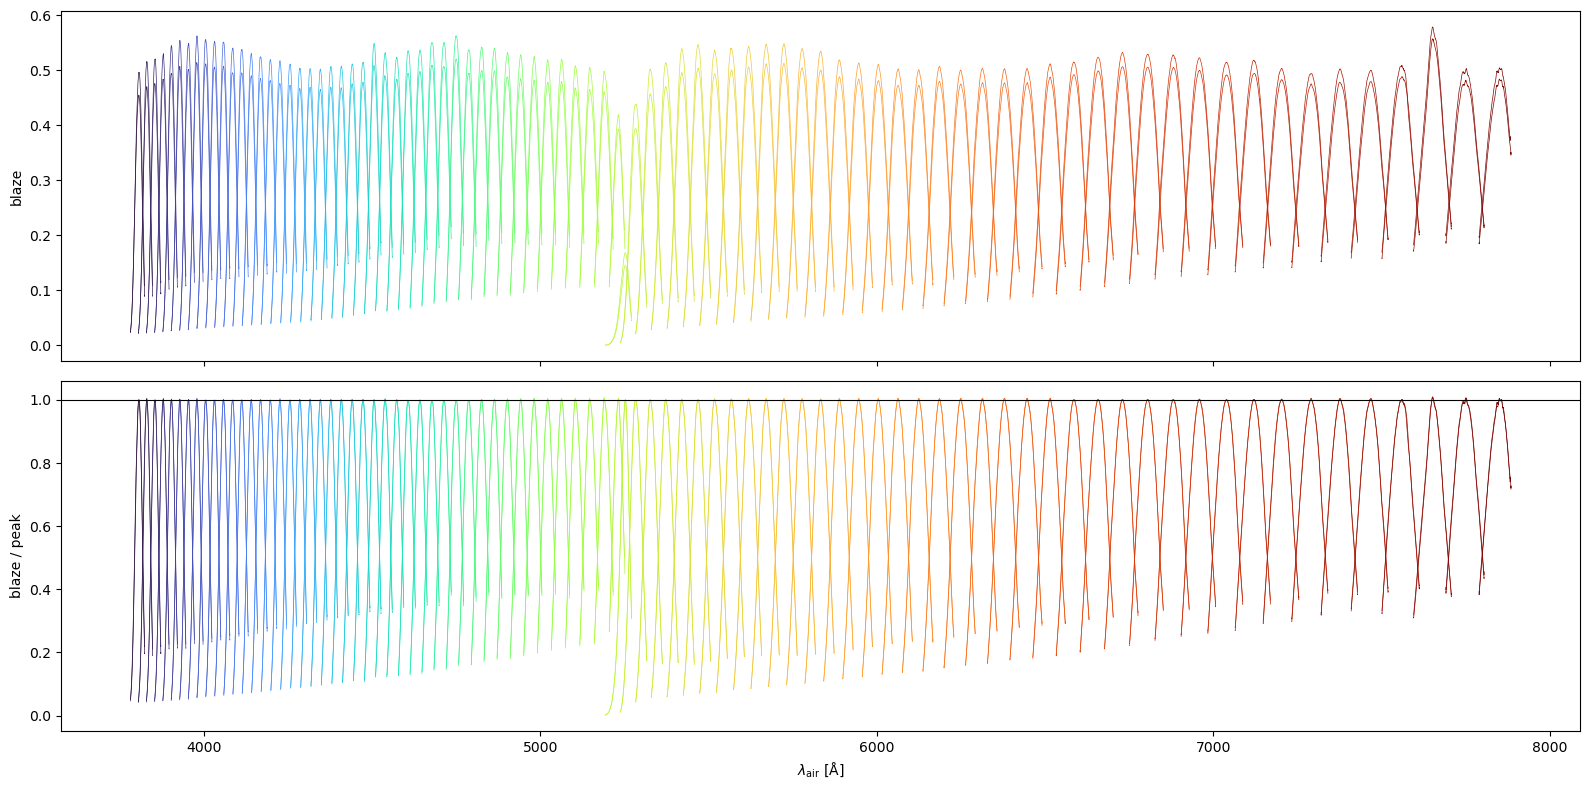

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for i in range(n_orders):
    color = cmap(i / (n_orders - 1))
    axes[0].plot(wave[i], blaze[i], lw=0.5, color=color)
    axes[1].plot(wave[i], blaze_norm[i], lw=0.5, color=color)
axes[0].set_ylabel('blaze')
axes[1].set_ylabel('blaze / peak')
axes[1].axhline(1, color='k', lw=0.8)
axes[1].set_xlabel(r'$\lambda_{\rm air}$ [Å]')
plt.tight_layout()
plt.show()

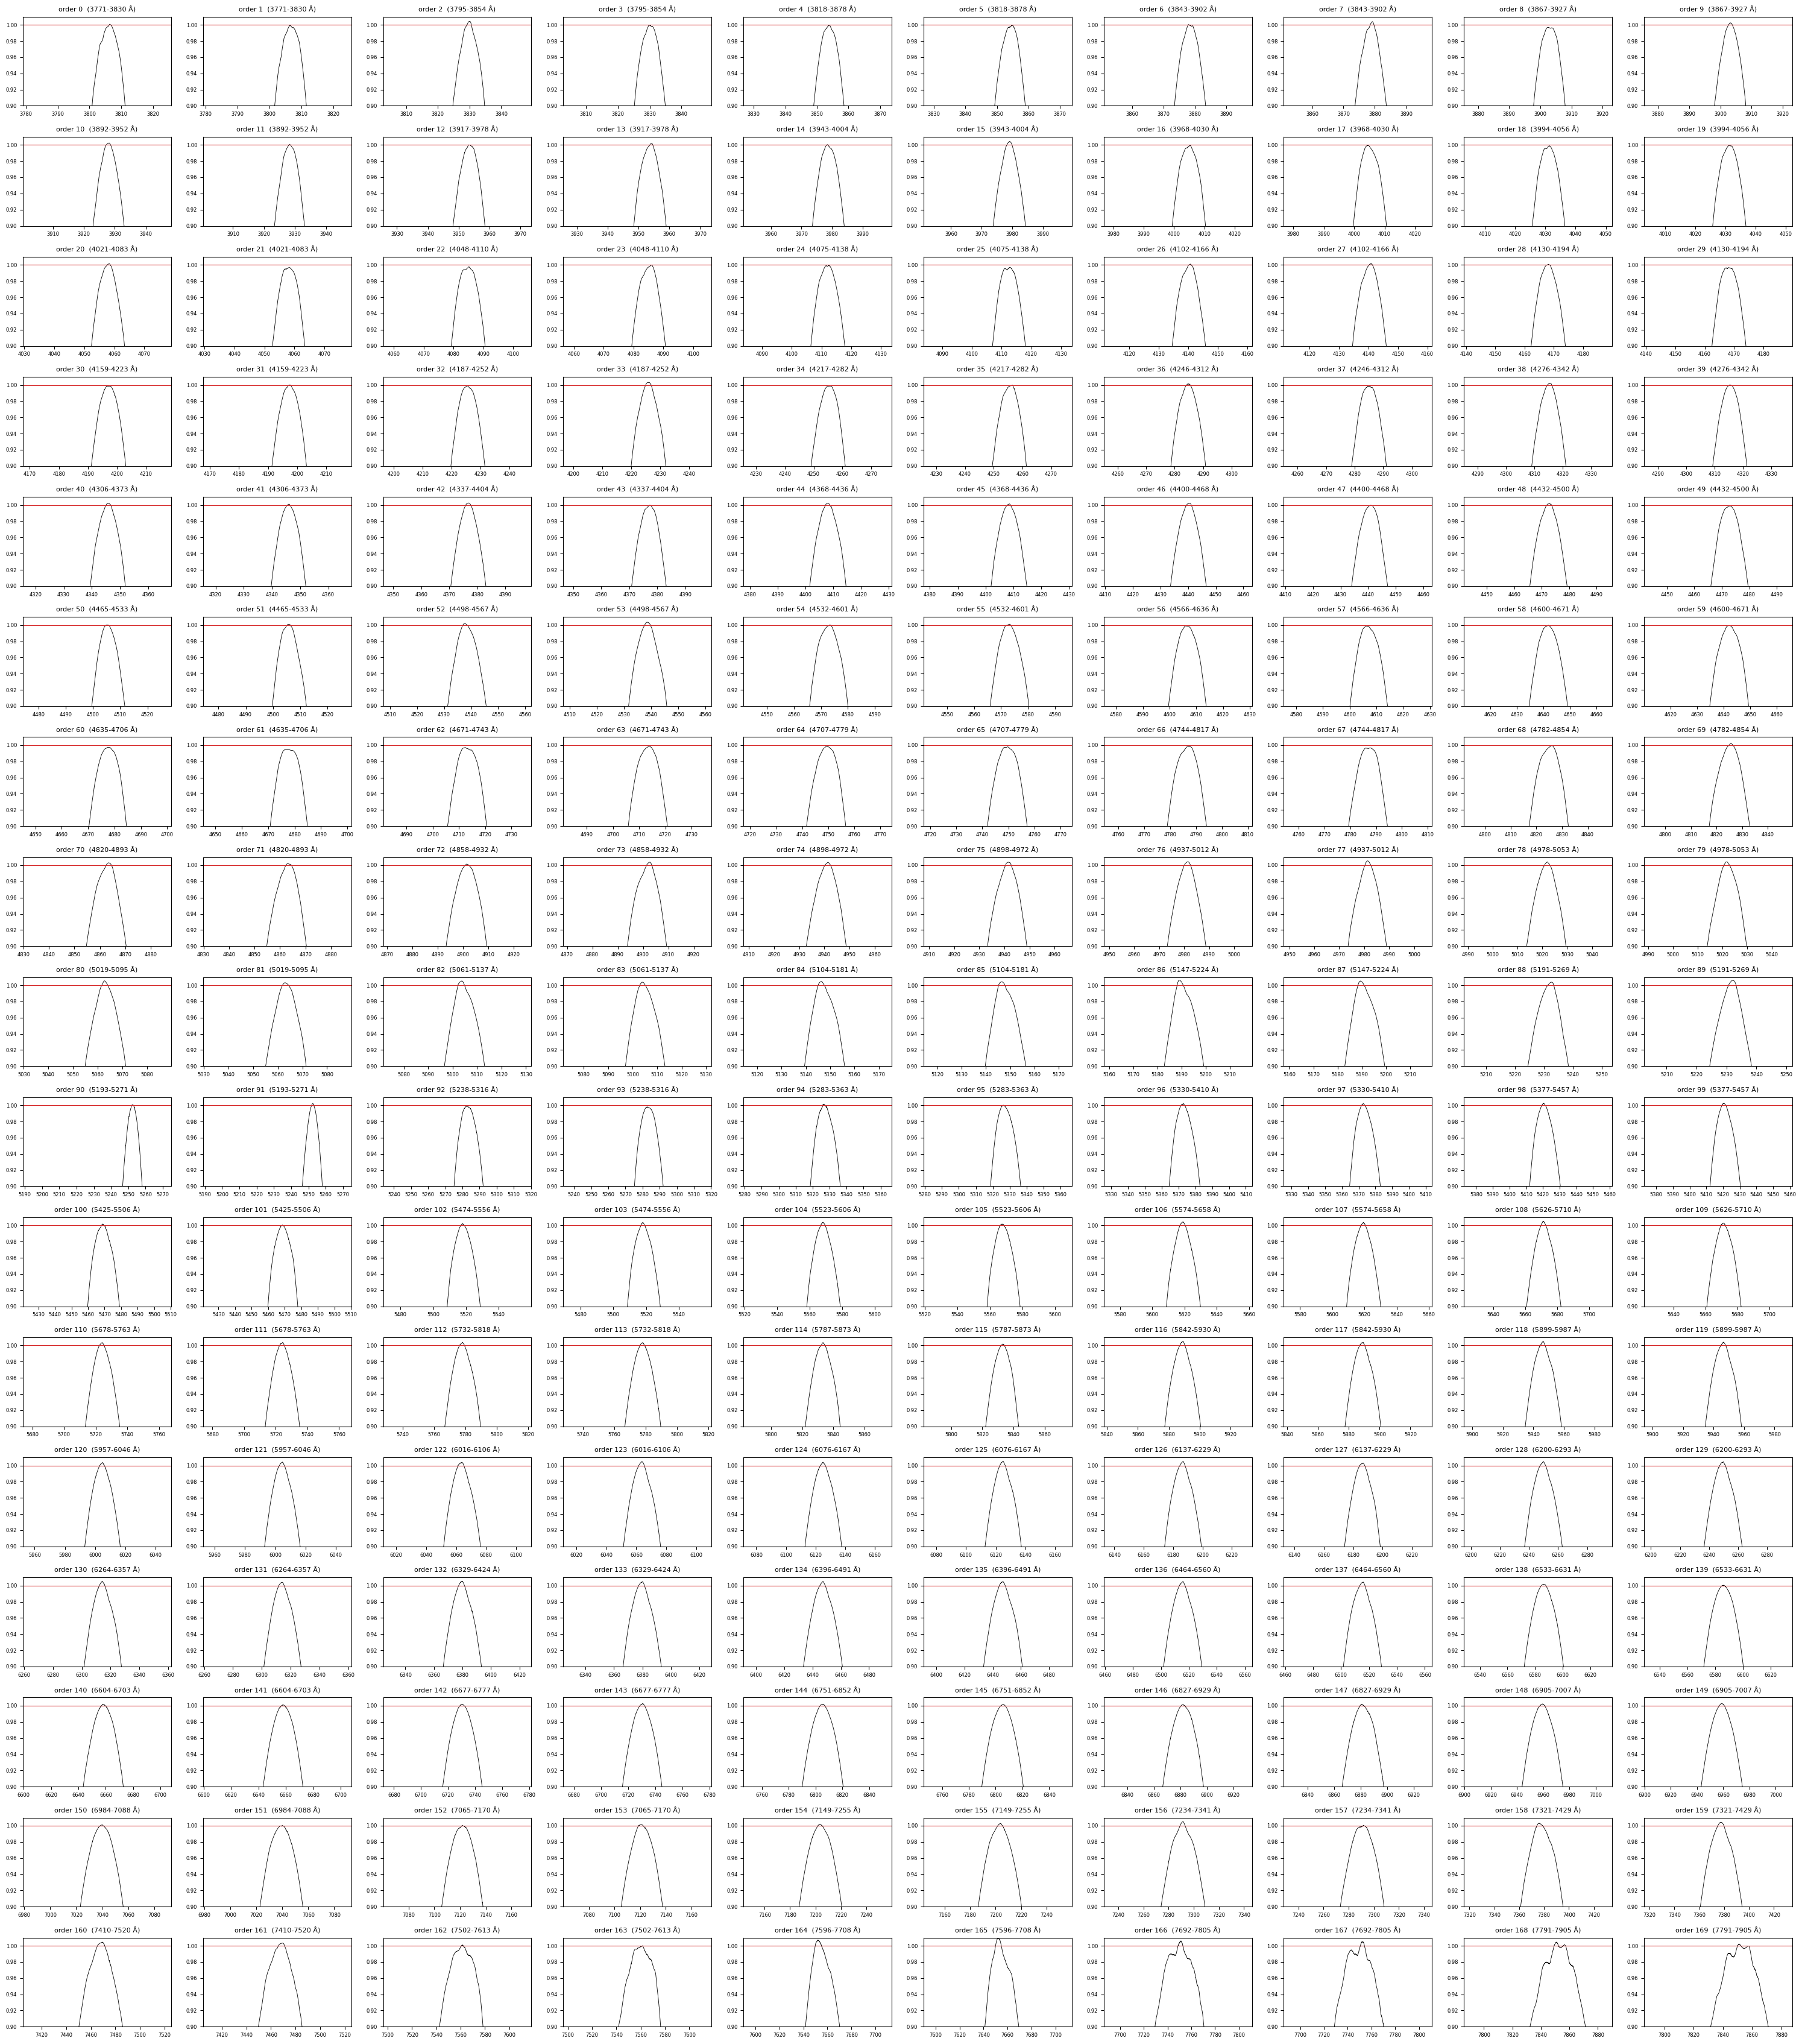

In [8]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2 * n_rows))
for i, ax in enumerate(axes.flat):
    if i >= n_orders:
        ax.axis('off')
        continue
    ax.plot(wave[i], blaze_norm[i], lw=0.6, color='k')
    ax.axhline(1, color='C3', lw=0.8)
    ax.set_ylim(0.9, 1.01)
    ax.set_title(f'order {i}  ({wave[i, 0]:.0f}-{wave[i, -1]:.0f} Å)', fontsize=8)
    ax.tick_params(labelsize=6)
plt.tight_layout()
plt.show()

## SunSim instrument file

In [9]:
from numpy.polynomial import chebyshev
from sunsim import INSTRUMENTS_DIR, Instrument

# vacuum wavelengths of every order: degree-9 Chebyshev polynomial of the pixel (x in [-1, 1])
deg = 9
n_pix = wave.shape[1]
x = np.linspace(-1, 1, n_pix)
wave_cheb = np.array([chebyshev.chebfit(x, w, deg) for w in data['wave_vac']])
resid = np.abs(np.array([chebyshev.chebval(x, c) for c in wave_cheb]) - data['wave_vac'])
print('max residual of the wavelengths %.1e A' % resid.max())

out_file = INSTRUMENTS_DIR / 'PoET_orders.npz'
np.savez_compressed(out_file, wave_vac_cheb=wave_cheb, n_pix=n_pix, blaze=blaze_norm.astype(np.float32))  # NaN: no blaze
print(out_file, '%.1f MB' % (out_file.stat().st_size / 1e6))

poet = Instrument.poet()
print(poet)
ok = np.isfinite(blaze_norm)
print('max wavelength difference (air) %.1e A' % max(np.abs(poet._to_medium(w, 'vacuum', 'air') - wave[j][ok[j]]).max()
                                                     for j, w in enumerate(poet.wave_orders)))

max residual of the wavelengths 1.6e-11 A


/Users/sophiestucki/sunsim/sunsim/data/instruments/PoET_orders.npz 4.5 MB
Instrument(PoET, R = 190000, 170 orders)
max wavelength difference (air) 1.3e-04 A
